# Creating PandaICT Networks

This Tutorial will introduce the user into the pandaict datastructure and how to create networks through the pandaict API. The following minimal example contains the most common elements that are supported by the Pandaict format.

The datastructure of the pandaict framework is based on the python library pandas. A pandaict network consist of a separate element table for each element type that is used in the network. Each element table consists of a column for each parameter and a row for each element. By executing the follwing code cells you generate the various element tables. You can find detailed descriptions about each parameter in the pandapower documentation under bulletpoint "Datastructures and Elements".

## pandaict package

In [ ]:
import pandaict as pi #import pandaict

## Empty Network

### Create Function
```python  
pandaict.create_empty_ict_network() #create an empty network  
```
This function initializes the pandaict datastructure.  

**Output:**  
**net** (attrdict) - PANDAICT attrdict with empty tables ?? Greift auf Pandapower zu daher vl Pandapower attrdict

**Example:**

In [ ]:
ict_net = pi.create_empty_ict_network() #create an empty network

## ICT - Node

### Create Function
```python 
create_ict_node(net, type=None, name=None, index=None, in_service=True)
```
Adds one node in table ict_net["node"].
Nodes are the nodes of the network that all other lements connect to.  

**Input:**  
**net**(pandaictNet) - The pandaict network in which the element is created

**Optional:**  
**type**(string, default None) - Type of the node  
**name**(string, default None) - The name for this node  
**index**(int, default None) - Force a specified ID if it is available. If None, the index one higher than the highest already  existing index is selected.  
**in_service**(boolean, default True) - True for in_service or False for out of service  

**Output:**  
**index**(int) - The unique ID of the created bus

**Example:**

In [3]:
node1 = pi.create_ict_node(ict_net, name="ICT Node 1")
node2 = pi.create_ict_node(ict_net, name="ICT Node 2")
node3 = pi.create_ict_node(ict_net, name="ICT Node 3")
node4 = pi.create_ict_node(ict_net, name="ICT Node 4")
node5 = pi.create_ict_node(ict_net, name="ICT Node 5")
node6 = pi.create_ict_node(ict_net, name="ICT Node 6")

In [3]:
ict_net.node #show node table

,name,type,in_service
0,ICT Node 1,None,True
1,ICT Node 2,None,True
2,ICT Node 3,None,True
3,ICT Node 4,None,True
4,ICT Node 5,None,True
5,ICT Node 6,None,True


## ICT - Link

### Create Function
```python 
create_ict_link(net, from_node, to_node, length_km, protocols, type="wired", name=None, index=None, in_service=True)
```
Creates a link element in net[“link”]. 

**Input:**  
**net**(pandaictNet) - The ict_net within this link should be created  
**from_node**(int) - ID of the node on one side which the link will be connected with  
**to_node**(int) - ID of the node on the other side which the link will be connected with  
**length_km**(float) - The link length in km  
**protocols**(string) - Name of the used transmission protocols  

**Optional:**  
**type**(string, default "wired") - Type of the link connection ("wired","wireless")  
**name**(string, default None) - The name for this link    
**index**(int, default None) - Force a specified ID if it is available. If None, the index one higher than the highest already  existing index is selected.  
**in_service**(boolean, default True) - True for in_service or False for out of service  

**Output:**  
**index**(int) - The unique ID of the created link

**Example:**

In [4]:
link1 = pi.create_ict_link(ict_net, node1, node2, protocols="TCP", length_km=1.0, type="wired", name="Link 1")
link2 = pi.create_ict_link(ict_net, node2, node3, protocols="TCP", length_km=1.0, type="wired", name="Link 2")
link3 = pi.create_ict_link(ict_net, node3, node4, protocols="TCP", length_km=1.0, type="wired", name="Link 3")
link4 = pi.create_ict_link(ict_net, node4, node5, protocols="TCP", length_km=1.0, type="wired", name="Link 4")
link5 = pi.create_ict_link(ict_net, node5, node6, protocols="TCP", length_km=1.0, type="wireless", name="Link 5")
link6 = pi.create_ict_link(ict_net, node6, node1, protocols="TCP", length_km=1.0, type="wireless", name="Link 6")

Link 5 and link 6 are classified as wireless links (type="wireless"), all other links are classified as wired links (type="wired")

In [5]:
ict_net.link #show link table

,name,from_node,to_node,length_km,type,protocols,in_service
0,Link 1,0,1,1.0,wired,TCP,True
1,Link 2,1,2,1.0,wired,TCP,True
2,Link 3,2,3,1.0,wired,TCP,True
3,Link 4,3,4,1.0,wired,TCP,True
4,Link 5,4,5,1.0,wireless,TCP,True
5,Link 6,5,0,1.0,wireless,TCP,True


## ICT - Device

### Create Function
```python 
create_ict_device(net, node, protocol, service, interconnects, name=None, index=None, type=None, in_service=True)
```
Creates a device element in net[“device”]. 

**Input:**  
**net**(pandaictNet) - The ict_net within this link should be created  
**node**(int) - ID of the node on which the device will be connected with  
**protocols**(string) - Name of the used transmission protocols  
**service**(int) -  Protection System (Datatyp noch ändern zu Object)  
**interconnects**(string) - Name of the Connected Device in Power Grid    

**Optional:**  
**name**(string, default None) - The name for this device  
**index**(int, default None) - Force a specified ID if it is available. If None, the index one higher than the highest already  existing index is selected.  
**type**(string, default "None") - Type of the device    
**in_service**(boolean, default True) - True for in_service or False for out of service  

**Output:**  
**index**(int) - The unique ID of the created device

**Example:**

In [5]:
device1 = pi.create_ict_device(ict_net, node1, protocol="TCP", service=1, interconnects="Trafo")
device2 = pi.create_ict_device(ict_net, node2, protocol="TCP", service=1, interconnects="switch")
device4 = pi.create_ict_device(ict_net, node4, protocol="TCP", service=1, interconnects="Generator")
device5 = pi.create_ict_device(ict_net, node5, protocol="TCP", service=1, interconnects="switch")
device6 = pi.create_ict_device(ict_net, node6, protocol="TCP", service=1, interconnects="switch")

## ICT - Node Geodata

We give the created nodes geodata for the plot

In [6]:
ict_net.node_geodata.loc[0, ["x", "y"]] = (0, 0)
ict_net.node_geodata.loc[1, ["x", "y"]] = (4, 0)
ict_net.node_geodata.loc[2, ["x", "y"]] = (4, 1)
ict_net.node_geodata.loc[3, ["x", "y"]] = (4, 2)
ict_net.node_geodata.loc[4, ["x", "y"]] = (0, 2)
ict_net.node_geodata.loc[5, ["x", "y"]] = (0, 1)

## Plot ICT - Network

### Collection Functions
```python 
create_ict_node_collection(ict_net, nodes=None, node_geodata=None, size=1, **kwargs)  
create_ict_link_collection(ict_net, links=None, use_node_geodata=True, **kwargs)  
create_ict_device_collection(ict_net, size=1., infofunc=None, orientation=0, picker=False, **kwargs)  
```
Creates a a matplotlib patch collection of pandaict nodes/links/servers

**Input:**  
**ict_net**(pandaictNet) - The pandaict network  

**Optional:**  
**nodes**(int, default None) - Collection of the nodes  
**node_geodata**(Dataframe, default None) - x,y geodatas to the nodes  
**size**(float, default 1) - Size of the nodes plot  
**links**(int, default None) - Collection of the links  
**use_node_geodata** (boolean, defaul True) - Use the node geodata for the plot  
**infofunc**(function, default None) - infofunction for the patch element  
**orientation**(float, default 0) - orientation of load collection. 0 is directed upwards, increasing values lead to clockwise direction changes.   
**picker**(boolean, default False) - picker argument passed to the patch collection  
****kwargs** -  key word arguments are passed to the patch function  

**Output:**  
**node_collection** - Patch collection of the nodes  
**link_collection** - Line collection of the links  
**device_collection** - server1,server2 patch collection  

**Example:**

<AxesSubplot:>

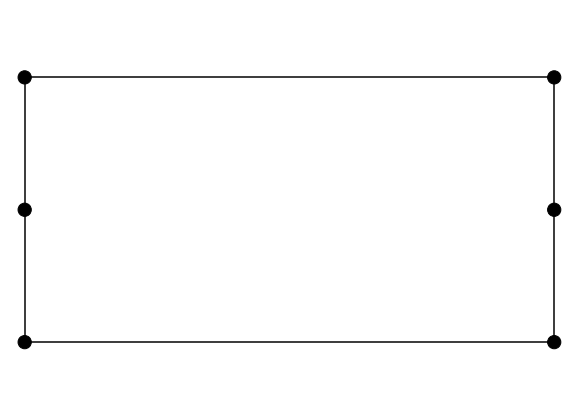

In [7]:
import pandapower.plotting as plot

pc = pi.create_ict_node_collection(ict_net, size= 0.05, color="black")
lc = pi.create_ict_link_collection(ict_net, color="black")

plot.draw_collections([lc, pc], figsize=(8,6))